# The data: a table and a map

<div class="roadmap"><div class="rm-sofar"><span>So far</span>Part 1 of the lecture: there is more data than anyone can read, and machine learning is a way to learn rules from it.</div><div class="rm-question"><b>What does the data look like?</b><span>One row per hexagon: 16 counts of points of interest (the features) and one land-use label. And one place per hexagon on the map.</span></div><div class="rm-steps"><div class="rm-step"><b>The table</b><span>features and label</span></div><div class="rm-step"><b>The map</b><span>where each row lies</span></div><div class="rm-step"><b>The label</b><span>a rule, not a measurement</span></div><div class="rm-step"><b>Neighbours</b><span>adjacent hexagons are alike</span></div></div></div>

The Helsinki region (Helsinki, Espoo, Vantaa and Kauniainen) is divided into 1,459 hexagons, each about 0.57 km². The hexagons are cells of H3, a grid of hexagons that covers the whole globe (week 7). A hexagon is one row of a table and one place on a map. Every page of this site uses this one dataset.

For every hexagon we know two things, both taken from OpenStreetMap:

- **Features:** how many points of interest (POIs) of 16 kinds lie inside it: food places, shops, schools, parking, benches, playgrounds, offices and so on. These 16 counts are the hexagon's **POI profile**.
- **Land-use label:** one of three classes. `green` (forest, parks, fields), `residential`, and `work` (commercial, retail and industrial areas).

The features come from OpenStreetMap's point data and the label from its land-use polygons, so the label is not simply a copy of a feature. The script `build_dataset.py` in the repository shows how the table was made.

```{note}
The code that made a table or a figure is folded above it: click *Show code cell source* to open it. The pages after this one continue the same notebook, so they use the variables defined here.
```

## The table

In [1]:
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier

import helpers as h
from helpers import CLASSES, COLORS, FEATURES

RES = 8      # H3 resolution of the hexagons: 8 (about 0.57 km² each in this region) or 9 (about 0.08 km² each)
SEED = 0     # change it and re-run: how much of a result is luck?
SAVE = os.environ.get("GEOAI_SAVE_FIGS") == "1"   # only used by the teacher, to export the pictures and sliders of the website

In [2]:
hexes = h.load_hexagons(RES)
print(f"{len(hexes):,} hexagons   {int(hexes[FEATURES].sum().sum()):,} points of interest")
print(hexes["landuse"].value_counts().to_string())

# Five hexagons that we follow through this part, and three of the 16 features:
# car = parking and fuel, play = playgrounds and similar, office = offices.
FIVE_PLACES = {"Otaniemi": (24.827, 60.186), "Tikkurila": (25.044, 60.292), "Kontula": (25.080, 60.235),
               "Seurasaari": (24.885, 60.183), "Nuuksio": (24.550, 60.300)}
FIVE = [h.hexagon_at(hexes, lon, lat) for lon, lat in FIVE_PLACES.values()]
SHOW = ["car", "play", "office"]
built_up_pct = ((hexes["share_residential"] + hexes["share_work"]) * 100).to_numpy()   # share of the hexagon that is built-up land
five_rows = hexes.loc[FIVE, ["municipality"] + SHOW + ["poi_total", "landuse"]].copy()
five_rows.insert(0, "place", list(FIVE_PLACES))
five_rows.insert(len(five_rows.columns) - 1, "built_up_pct", built_up_pct[FIVE].round(0))
five_rows.index = range(1, 6)
five_rows

1,459 hexagons   73,404 points of interest
landuse
green          747
residential    569
work           143


,place,municipality,car,play,office,poi_total,built_up_pct,landuse
1,Otaniemi,Espoo,92,2,15,305,28.0,work
2,Tikkurila,Vantaa,64,13,16,338,42.0,residential
3,Kontula,Helsinki,26,7,0,98,59.0,residential
4,Seurasaari,Helsinki,0,7,0,124,0.0,green
5,Nuuksio,Espoo,1,7,0,13,2.0,green


This table is the whole dataset as a model sees it. The count columns are what we know about a hexagon, the **features**, written `X`. The last two columns are things we may want to predict, written `y`.

There are two kinds of question, and the last two columns show one of each.

- **Classification:** the answer is a category. *Which land use does the hexagon have: green, residential or work?* The answer is called a **label**, and a model is scored by its **accuracy**, the share of hexagons it labels correctly. Most pages of this site ask this question.
- **Regression:** the answer is a number. *How much of the hexagon is built-up land?* A model is scored by how far its numbers are from the true ones, for example by **R²**, which the page on supervised learning explains.

The two columns are related: the land-use label is the built-up share turned into a category (the rule is explained below). Interpolation in week 8, with inverse distance weighting or kriging, was regression too: it predicts a number at a place without a measurement.

## The map

A table has no geography in it: the rows could be shuffled and nothing would change. The same five rows have a place on the map.

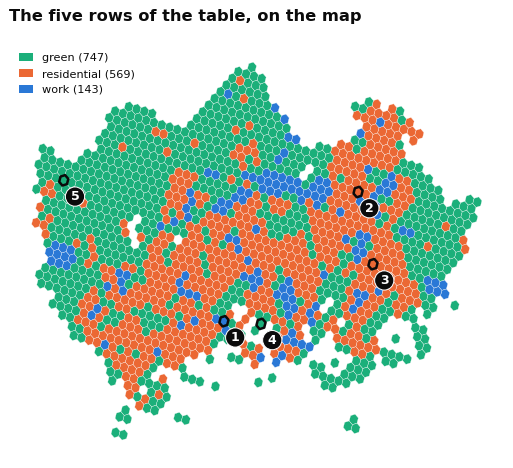

In [3]:
fig, ax = plt.subplots(figsize=(8.6, 6))
h.map_classes(hexes, hexes["landuse"], ax=ax, title="The five rows of the table, on the map", places=False)
h.number_hexagons(ax, hexes, FIVE)
h.save(fig, "0_five_rows_map.png", SAVE)
plt.show()

Point at a hexagon on the map below to read its row of the table. The colour is the land-use label: green for `green`, orange for `residential`, blue for `work`. Zoom in to see the streets, buildings and parks that the counts and the label were taken from.

<iframe src="_static/maps/hexagons.html" class="webmap" title="Interactive map of the hexagons"></iframe>

*Map data and background map © OpenStreetMap contributors.*

In [4]:
if SAVE:    # the interactive map of the website
    h.web_map(hexes, {"municipality": "municipality", "poi_total": "points of interest, all 16 kinds", "car": "parking and fuel",
                      "play": "playgrounds", "office": "offices", "food": "food places", "shop_daily": "daily shops", "education": "schools"})

And here is the whole table on two maps: the label, and how many points of interest a hexagon has.

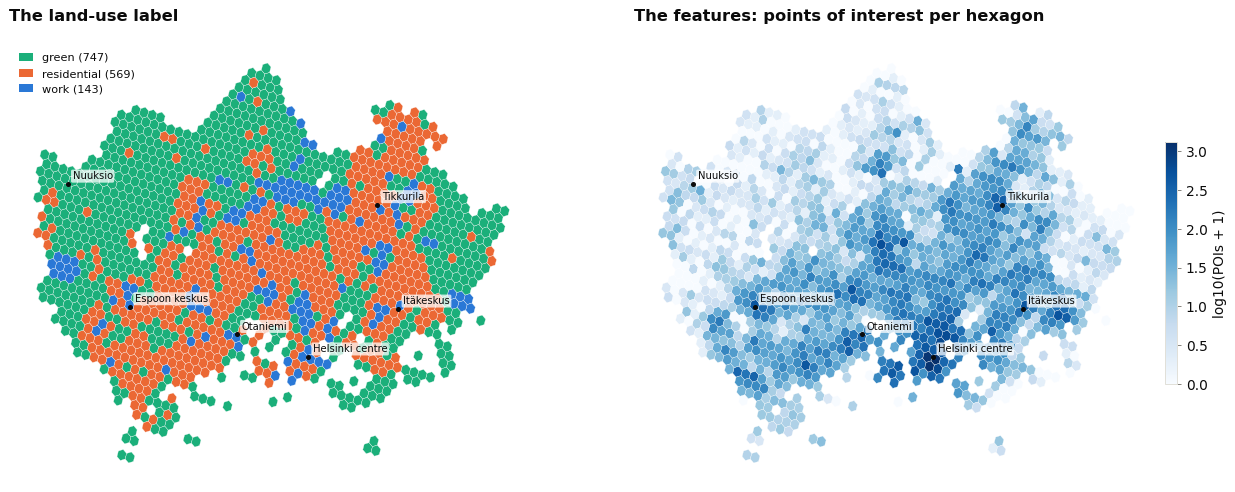

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, hexes["landuse"], ax=axes[0], title="The land-use label")
h.map_values(hexes, np.log10(hexes["poi_total"] + 1), ax=axes[1],
             title="The features: points of interest per hexagon", label="log10(POIs + 1)")
plt.tight_layout()
h.save(fig, "0_data_maps.png", SAVE)
plt.show()

The 16 counts of one hexagon, the one that contains the Otaniemi campus, look like this.

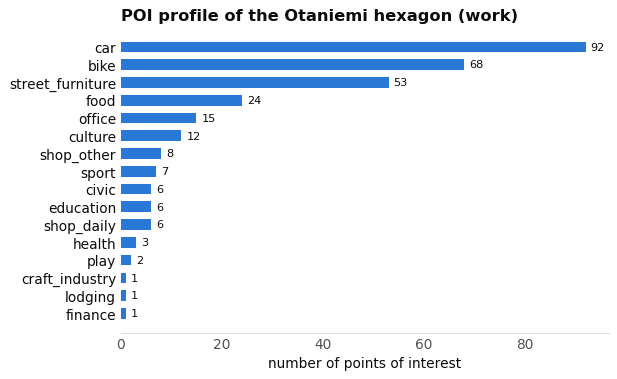

In [6]:
q_otaniemi = h.hexagon_at(hexes, 24.827, 60.186)
profile = hexes.loc[q_otaniemi, FEATURES].astype(float).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(profile.index, profile.values, height=0.6, color="#2a78d6")
for name, v in profile.items():
    ax.text(v + 1, name, f"{int(v)}", va="center", fontsize=9)
ax.set_title(f"POI profile of the Otaniemi hexagon ({hexes.loc[q_otaniemi, 'landuse']})")
ax.set_xlabel("number of points of interest")
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
h.save(fig, "0_profile_otaniemi.png", SAVE)
plt.show()

## The label is a rule

**The label is a rule, not a measurement.** A hexagon of about 0.57 km² usually holds several land uses, and we give it one name: at least 20% built-up land makes it `residential` or `work`, whichever covers more, and everything else is `green`. How much does that rule decide?

In [7]:
built = hexes["share_residential"] + hexes["share_work"]


def label_with(rule):
    return np.where(built < rule, "green", np.where(hexes["share_work"] >= hexes["share_residential"], "work", "residential"))


assert (label_with(0.20) == hexes["landuse"]).all()
mixed = ((hexes["share_residential"] >= 0.2) & (hexes["share_green"] >= 0.2)).mean()
print(f"{mixed:.0%} of the hexagons are at least 20% residential and at least 20% green.")
for rule in (0.10, 0.30):
    print(f"With a {rule:.0%} rule in place of the 20% rule, {np.mean(label_with(rule) != hexes['landuse']):.0%} of the labels change.")

32% of the hexagons are at least 20% residential and at least 20% green.
With a 10% rule in place of the 20% rule, 13% of the labels change.
With a 30% rule in place of the 20% rule, 12% of the labels change.


> **What did we just see?** Many hexagons are mixed, and a different, equally reasonable rule would name roughly one hexagon in eight differently. The label is also drawn by volunteers. We therefore speak of the *land-use label* and never of the truth, and we should not expect any model to reach 100%.

## Neighbours are alike

The last step prepares the four matrices that the other pages use.

- `X` · the POI profiles, one row per hexagon. We take `log(1 + count)` because a few hexagons in the centre have hundreds of POIs and most have a handful.
- `y` · the land-use label.
- `W` · the **spatial weights matrix** from week 3. Row *i* has the value 1/k for each of the *k* hexagons touching hexagon *i*.
- `X_around` · the **neighbours' profile**: `W @ X`, the average POI profile of the adjacent hexagons. In week 3 this was called the spatial lag.

In [8]:
X = np.log1p(hexes[FEATURES].to_numpy(float))    # own POI profile, 16 numbers per hexagon
y = hexes["landuse"].to_numpy()                  # land-use label
xy = hexes[["x", "y"]].to_numpy()                # centroid coordinates in metres
W = h.neighbour_matrix(hexes)                    # spatial weights (row-standardised)
X_around = W @ X                                 # the neighbours' profile

same_as_neighbours = np.mean([np.mean(y[W[i].indices] == y[i]) for i in range(len(y)) if W[i].nnz])
by_chance = (pd.Series(y).value_counts(normalize=True) ** 2).sum()
print(f"A hexagon shares its land-use label with {same_as_neighbours:.0%} of its neighbours.")
print(f"If the labels were scattered over the map at random, that would be {by_chance:.0%}.")

A hexagon shares its land-use label with 69% of its neighbours.
If the labels were scattered over the map at random, that would be 42%.


> **What did we just see?** Spatial dependence in one number (Tobler's first law, week 3). Adjacent hexagons are far more alike than chance would make them, so a hexagon without a label is not a hexagon about which we know nothing. The pages on semi-supervised learning, on self-supervised learning and on spatially explicit models borrow from that fact, and the page on challenges has to guard against it.